<a href="https://colab.research.google.com/github/SitiMutmainah15/PCVK_GENAP_2026/blob/main/week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# Import folder dari Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

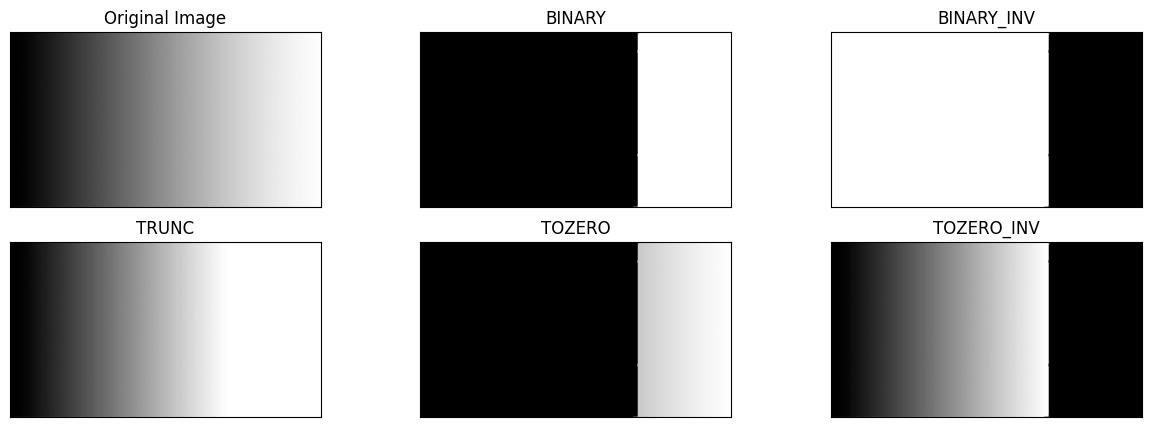

In [5]:
# Global Threshold Manual
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Membaca gambar gradient
filename = ('/content/drive/MyDrive/PCVK/Images/gradient.jpg')

img = cv.imread(filename, 0)  # grayscale

# Nilai threshold
thresh = 200
maxval = 255


# 1. BINARY Threshold Manual
binary = np.where(img > thresh, maxval, 0)


# 2. BINARY_INV Threshold Manual
binary_inv = np.where(img > thresh, 0, maxval)


# 3. TRUNC Threshold Manual
trunc = np.where(img > thresh, thresh, img)


# 4. TOZERO Threshold Manual
tozero = np.where(img > thresh, img, 0)


# 5. TOZERO_INV Threshold Manual
tozero_inv = np.where(img > thresh, 0, img)


# Menampilkan hasil
titles = [
    'Original Image',
    'BINARY',
    'BINARY_INV',
    'TRUNC',
    'TOZERO',
    'TOZERO_INV'
]

images = [
    img,
    binary,
    binary_inv,
    trunc,
    tozero,
    tozero_inv
]


plt.figure(figsize=(15,5))

for i in range(len(images)):
    plt.subplot(2,3,i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])

plt.show()

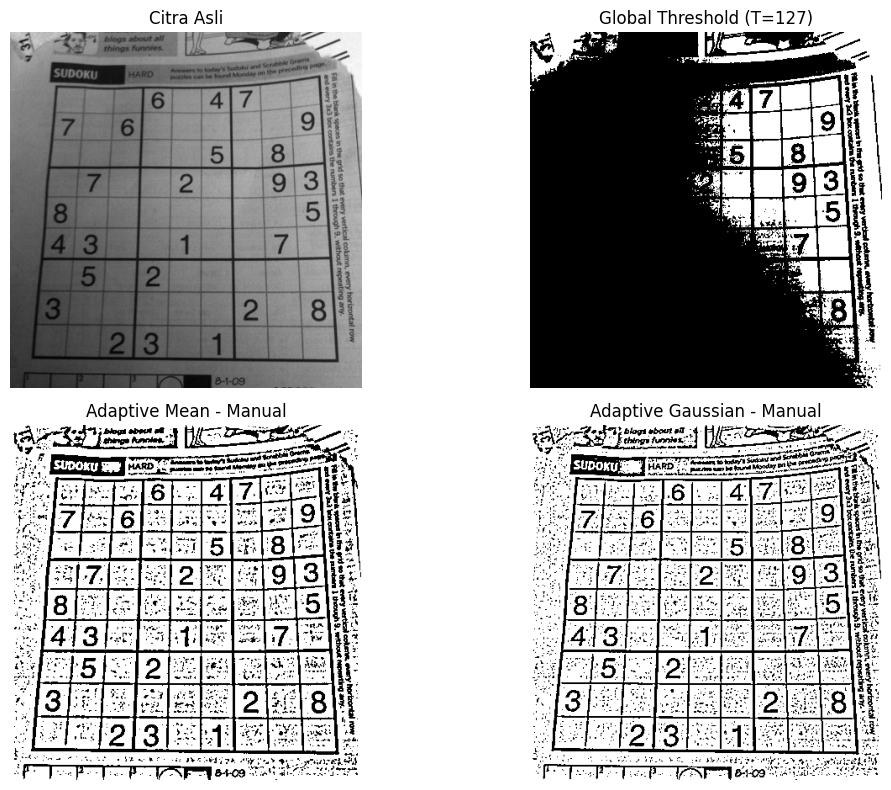

In [6]:
# Adaptive Threshold Manual
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import math


# Membaca citra Sudoku
filename = ('/content/drive/MyDrive/PCVK/Images/sudoku-original.jpg')

img = cv.imread(filename, 0)  # grayscale


# Parameter
global_thresh = 127
block_size = 11
C = 2
sigma = 2


# 1. Global Threshold Manual
global_manual = np.where(img > global_thresh, 255, 0)


# Fungsi Padding
def padding_image(image, size):
    pad = size // 2
    return np.pad(image, pad, mode='constant', constant_values=0)

#2. adaptive mean
def adaptive_mean(image, block_size, C):

    padded = padding_image(image, block_size)
    result = np.zeros_like(image)

    offset = block_size // 2

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):

            window = padded[i:i+block_size,
                            j:j+block_size]

            mean = np.mean(window)

            if image[i,j] > mean - C:
                result[i,j] = 255
            else:
                result[i,j] = 0

    return result



#gausian kernel
def gaussian_kernel(size, sigma):

    kernel = np.zeros((size,size))
    center = size//2

    total = 0

    for x in range(size):
        for y in range(size):

            value = math.exp(
                -((x-center)**2+(y-center)**2)
                /(2*sigma**2)
            )

            kernel[x,y] = value
            total += value

    return kernel/total


#3. adaptive gausian
def adaptive_gaussian(image, block_size, C, sigma):

    padded = padding_image(image, block_size)
    kernel = gaussian_kernel(block_size, sigma)

    result = np.zeros_like(image)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):

            window = padded[i:i+block_size,
                            j:j+block_size]

            gaussian_mean = np.sum(window * kernel)

            if image[i,j] > gaussian_mean - C:
                result[i,j] = 255
            else:
                result[i,j] = 0

    return result



# Proses
adaptive_mean_result = adaptive_mean(
    img,
    block_size,
    C
)


adaptive_gaussian_result = adaptive_gaussian(
    img,
    block_size,
    C,
    sigma
)

#tampil hasil

titles = [
    'Citra Asli',
    'Global Threshold (T=127)',
    'Adaptive Mean - Manual',
    'Adaptive Gaussian - Manual'
]


images = [
    img,
    global_manual,
    adaptive_mean_result,
    adaptive_gaussian_result
]


plt.figure(figsize=(12,8))

for i in range(len(images)):

    plt.subplot(2,2,i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')


plt.tight_layout()
plt.show()

Threshold Otsu = 93


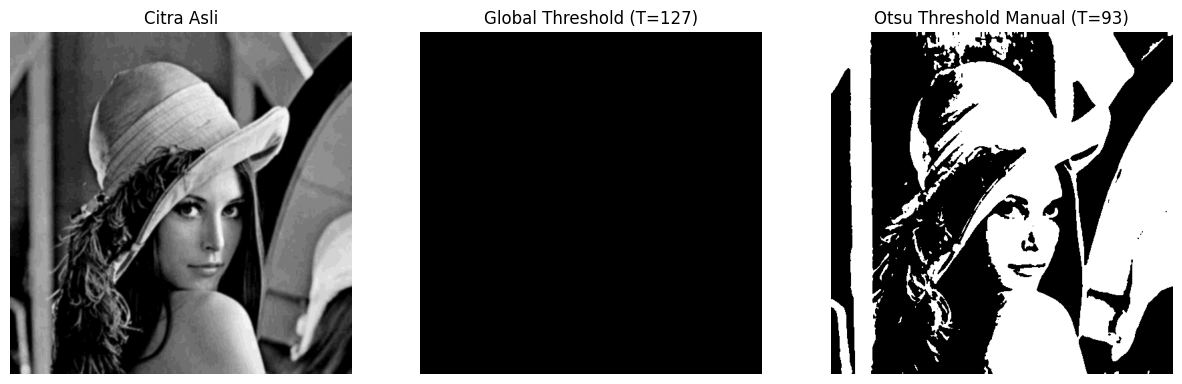

In [7]:
# Otsu Thresholding Manual (tanpa library)

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt


# Membaca gambar
filename = ('/content/drive/MyDrive/PCVK/Images/lena_gs_lc2.jpg')

img = cv.imread(filename, 0)


# Gaussian Blur
blur = cv.GaussianBlur(img,(5,5),0)


# Global threshold manual
thresh = 127


def otsu(gray):

    # jumlah pixel
    pixel_number = gray.shape[0] * gray.shape[1]

    mean_weight = 1.0 / pixel_number


    # Histogram
    his, bins = np.histogram(
        gray,
        np.arange(0,257)
    )


    final_thresh = -1
    final_value = -1


    intensity_arr = np.arange(256)


    # mencari threshold terbaik
    for t in bins[1:-1]:

        # Background
        pcb = np.sum(his[:t])

        # Foreground
        pcf = np.sum(his[t:])


        Wb = pcb * mean_weight
        Wf = pcf * mean_weight


        # Hindari pembagian nol
        if pcb == 0 or pcf == 0:
            continue


        mub = np.sum(
            intensity_arr[:t] * his[:t]
        ) / float(pcb)


        muf = np.sum(
            intensity_arr[t:] * his[t:]
        ) / float(pcf)


        # Between class variance
        value = Wb * Wf * (mub - muf) ** 2


        if value > final_value:
            final_thresh = t
            final_value = value



    # Membuat citra biner
    final_img = gray.copy()

    print("Threshold Otsu =", final_thresh)


    final_img[gray > final_thresh] = 255
    final_img[gray <= final_thresh] = 0


    return final_img, final_thresh



# Jalankan Otsu manual
otsu_binary, otsu_thresh = otsu(blur)



# Global threshold biasa
global_binary = np.where(
    blur > thresh,
    255,
    0
)



# Menampilkan hasil

titles = [
    'Citra Asli',
    'Global Threshold (T=127)',
    "Otsu Threshold Manual (T="+str(otsu_thresh)+")"
]


images = [
    blur,
    global_binary,
    otsu_binary
]


plt.figure(figsize=(15,5))


for i in range(3):

    plt.subplot(1,3,i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')


plt.show()

Threshold Otsu = 166


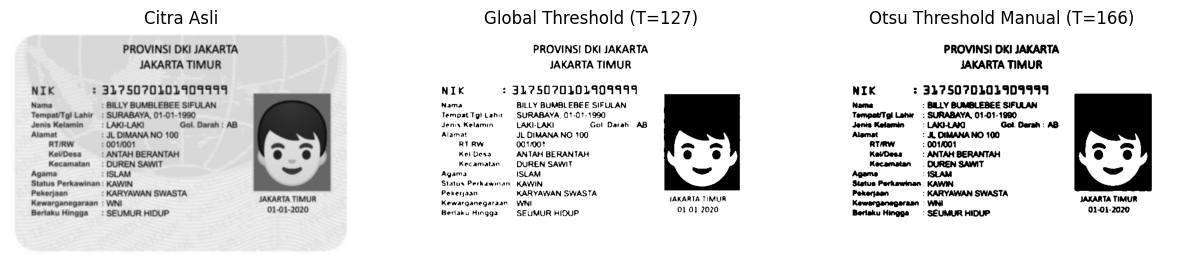

In [8]:
# Otsu Thresholding Manual (tanpa library)

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt


# Membaca gambar
filename = ('/content/drive/MyDrive/PCVK/Images/ktp_fulan.jpg')

img = cv.imread(filename, 0)


# Gaussian Blur
blur = cv.GaussianBlur(img,(5,5),0)


# Global threshold manual
thresh = 127


def otsu(gray):

    # jumlah pixel
    pixel_number = gray.shape[0] * gray.shape[1]

    mean_weight = 1.0 / pixel_number


    # Histogram
    his, bins = np.histogram(
        gray,
        np.arange(0,257)
    )


    final_thresh = -1
    final_value = -1


    intensity_arr = np.arange(256)


    # mencari threshold terbaik
    for t in bins[1:-1]:

        # Background
        pcb = np.sum(his[:t])

        # Foreground
        pcf = np.sum(his[t:])


        Wb = pcb * mean_weight
        Wf = pcf * mean_weight


        # Hindari pembagian nol
        if pcb == 0 or pcf == 0:
            continue


        mub = np.sum(
            intensity_arr[:t] * his[:t]
        ) / float(pcb)


        muf = np.sum(
            intensity_arr[t:] * his[t:]
        ) / float(pcf)


        # Between class variance
        value = Wb * Wf * (mub - muf) ** 2


        if value > final_value:
            final_thresh = t
            final_value = value



    # Membuat citra biner
    final_img = gray.copy()

    print("Threshold Otsu =", final_thresh)


    final_img[gray > final_thresh] = 255
    final_img[gray <= final_thresh] = 0


    return final_img, final_thresh



# Jalankan Otsu manual
otsu_binary, otsu_thresh = otsu(blur)



# Global threshold biasa
global_binary = np.where(
    blur > thresh,
    255,
    0
)



# Menampilkan hasil

titles = [
    'Citra Asli',
    'Global Threshold (T=127)',
    "Otsu Threshold Manual (T="+str(otsu_thresh)+")"
]


images = [
    blur,
    global_binary,
    otsu_binary
]


plt.figure(figsize=(15,5))


for i in range(3):

    plt.subplot(1,3,i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')


plt.show()

Mengapa Global Binary Threshold Lena menghasilkan gambar hitam semua?
Hasil menjadi hitam semua karena nilai threshold 127 terlalu tinggi dibandingkan intensitas piksel pada citra Lena low contrast. Sebagian besar piksel memiliki nilai di bawah 127, sehingga dianggap sebagai background dan diubah menjadi 0 (hitam).

Berapa nilai ambang batas (threshold) agar gambar Lena masih terlihat?
Nilai threshold harus lebih rendah dari 127 agar objek masih dapat dipisahkan. Berdasarkan hasil Otsu, threshold yang cocok berada sekitar 90-an, sehingga objek dan background masih terlihat jelas.

Perbandingan hasil Global Threshold dan Otsu Threshold
Global Threshold menggunakan nilai tetap (127), sehingga kurang cocok untuk citra dengan kontras rendah. Sedangkan Otsu dapat menentukan nilai threshold secara otomatis berdasarkan histogram, sehingga hasil segmentasi lebih baik dan objek lebih terlihat.


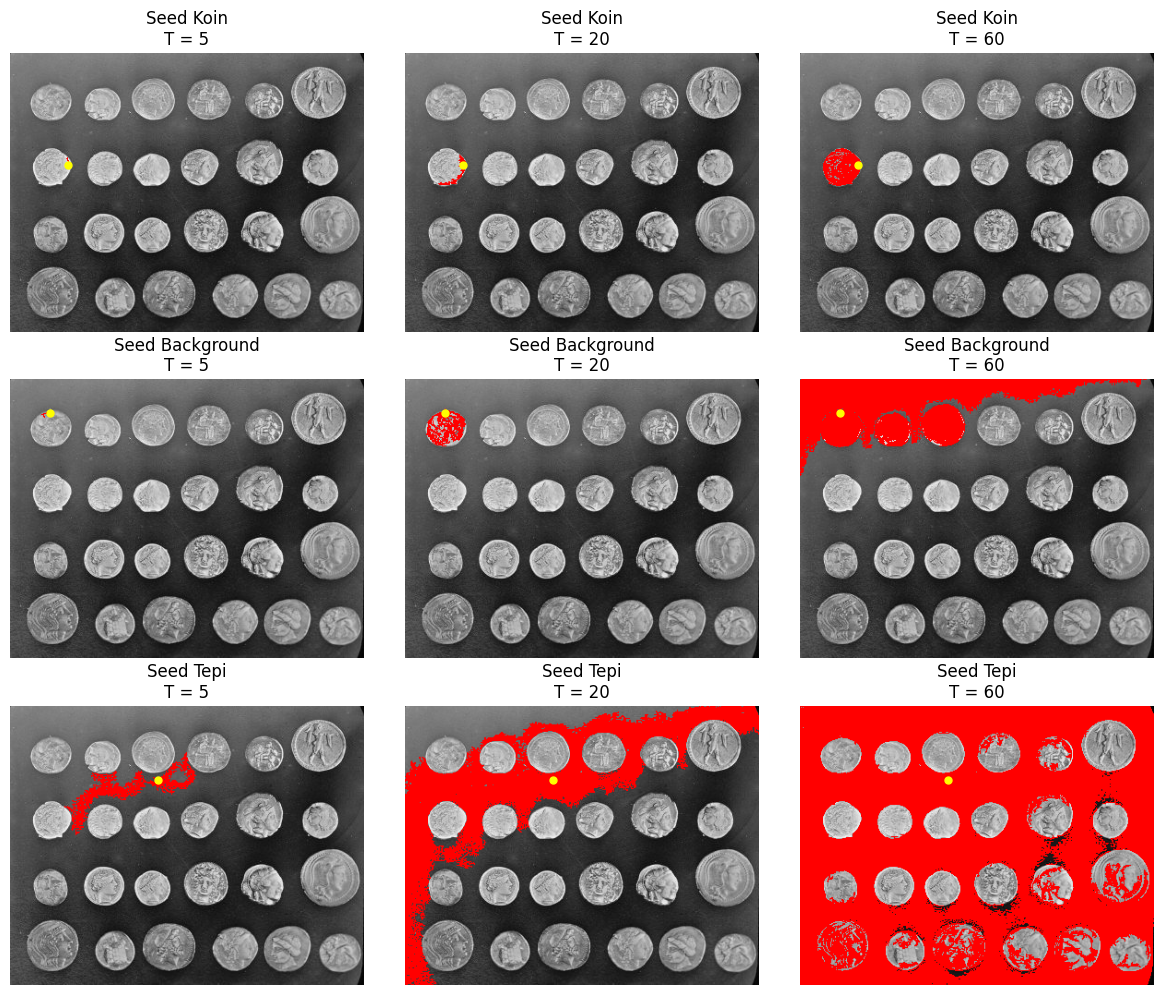

In [14]:
# Segmentasi Region Growing data.coins()

import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.segmentation import flood


# Membaca citra
gray = data.coins()


# Menentukan seed
# (baris, kolom)
seed_koin = (121, 63)        # dalam koin
seed_background = (36, 43)   # latar
seed_tepi = (80, 160)        # tepi koin


seeds = [
    ("Seed Koin", seed_koin),
    ("Seed Background", seed_background),
    ("Seed Tepi", seed_tepi)
]


# Nilai tolerance
T_values = [5, 20, 60]


# Membuat grid 3x3
plt.figure(figsize=(12,10))


index = 1


for nama, seed in seeds:

    for T in T_values:


        # Region growing
        region = flood(
            gray,
            seed_point=seed,
            tolerance=T,
            connectivity=1
        )


        # Membuat overlay seperti contoh modul
        hasil = np.stack([gray]*3, axis=-1)

        hasil[region] = [255,0,0]


        plt.subplot(3,3,index)

        plt.imshow(hasil)

        # tanda seed
        plt.scatter(
            seed[1],
            seed[0],
            color='yellow',
            s=25
        )


        plt.title(
            nama + "\nT = " + str(T)
        )

        plt.axis('off')


        index += 1



plt.tight_layout()
plt.show()

Berdasarkan hasil segmentasi, nilai tolerance memengaruhi luas region yang terbentuk. Tolerance kecil menghasilkan area yang lebih terbatas karena hanya piksel dengan intensitas yang mirip dengan seed yang diterima. Semakin besar tolerance, semakin luas region yang terbentuk, namun risiko piksel yang bukan bagian objek ikut tersegmentasi juga meningkat.

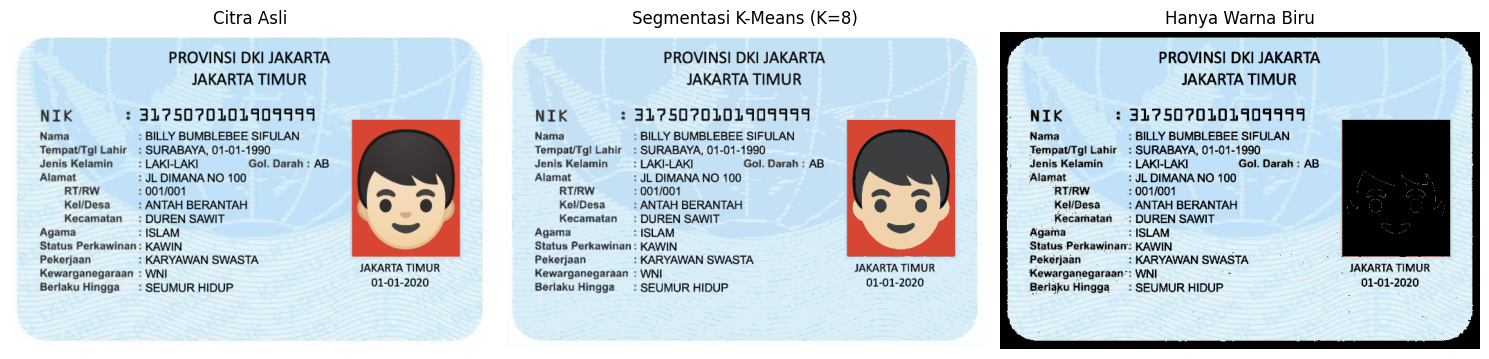

In [17]:
# Segmentasi Warna Biru pada KTP menggunakan K-Means

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Membaca citra KTP

filename = '/content/drive/MyDrive/PCVK/Images/ktp_fulan.jpg'

img = cv.imread(filename)

# BGR ke RGB
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# K-Means Segmentasi

# Ubah gambar menjadi data piksel
Z = img_rgb.reshape((-1,3))

Z = np.float32(Z)


# Jumlah cluster sesuai modul
k = 8


kmeans = KMeans(
    n_clusters=k,
    random_state=42
)


kmeans.fit(Z)



# Ambil label dan centroid
labels = kmeans.labels_

centers = np.uint8(
    kmeans.cluster_centers_
)



# Membentuk citra hasil K-Means
segmented = centers[labels.flatten()]

segmented_img = segmented.reshape(
    img_rgb.shape
)


# Mengambil warna biru

# Konversi hasil K-Means ke HSV

hsv = cv.cvtColor(
    segmented_img,
    cv.COLOR_RGB2HSV
)


H, S, V = cv.split(hsv)

# Rentang warna biru sesuai modul

kelompok_biru = np.where(
    (H >= 85) &
    (H <= 130) &
    (S >= 25) &
    (V >= 40)
)

# Membuat background hitam

hasil_biru = np.zeros_like(
    img_rgb
)

# Mempertahankan hanya warna biru

hasil_biru[kelompok_biru] = img_rgb[kelompok_biru]


# Menampilkan hasil

plt.figure(figsize=(15,5))


# Citra asli
plt.subplot(1,3,1)

plt.imshow(img_rgb)

plt.title("Citra Asli")

plt.axis('off')


# K-Means
plt.subplot(1,3,2)

plt.imshow(segmented_img)

plt.title("Segmentasi K-Means (K=8)")

plt.axis('off')


# Hanya biru
plt.subplot(1,3,3)

plt.imshow(hasil_biru)

plt.title("Hanya Warna Biru")

plt.axis('off')


plt.tight_layout()

plt.show()

Segmentasi warna menggunakan K-Means (K=8) berhasil memisahkan kelompok warna pada citra KTP. Berdasarkan rentang HSV, area berwarna biru dapat dipertahankan sedangkan warna lain dihilangkan. Hasil menunjukkan bahwa metode ini cukup efektif untuk mendeteksi warna biru, meskipun beberapa bagian masih terdeteksi akibat kemiripan nilai warna dengan objek utama.